# MJ-Lens: decode words from image regions across layers

Run **Qwen2.5-VL-3B-Instruct** on the technical report's original image/question inputs. The main experiment reads words from visual tokens overlapping the two annotated **GQA shirt bboxes**, and follows those raw vocabulary predictions across selected decoder layers. Candidate words are not restricted to answer labels. Additional MMVP, VSR and VisOnlyQA cases remain supplementary model-output controls.

For every bbox, keep **all positive-area bbox/patch intersections** in the native processed image grid. Decode each patch against the complete vocabulary. The region summary averages each patch's full softmax distribution with weights proportional to its bbox intersection area; it does not decode an averaged hidden vector or average Top-k lists. Exports retain raw token strings/reprs, IDs, probabilities, per-patch logits, native coordinates and post-hoc reference-word ranks. No punctuation, whitespace, special tokens or implausible candidates are filtered out.

Two MJ operators are calibrated: **V→T** reads decoder image-token states, and **T→T** reads the last prompt state. In this checkpoint's image-before-question order, earlier image states cannot see the later question. The bbox words are contextual vocabulary readouts, not isolated patch captions or a causal localization test. The selected-word Yellow−Black heatmaps and last-text-position comparisons are supplementary experiments.

The default exact calibration uses **32 independent COCO image/caption pairs**, from an internal partition of official **COCO val2014**. The eight report images remain held out. Native input processing, caption teacher forcing, target masks, fitting/resume, fresh model calls, decoding, data export and visualization are all visible below. No saved showcase tensors or rendered figures are loaded.

Install from this checkout with `python -m pip install -e ".[transformers,visualization,notebooks]"`, then select that Python kernel. A CUDA GPU with **24 GB or more** is recommended for the float32, eager-attention exact-VJP protocol. A fresh 32-image fit takes roughly 15 minutes or more on an A100-class GPU; matching calibration checkpoints can resume. An empty output directory performs a new fit. CPU execution is much slower.

| Configuration | Default | Meaning |
| --- | --- | --- |
| `VLM_PROBING_OUTPUT` | `outputs/mj_bbox_readouts` | Fresh fitted artifacts, region JSON/CSV, supplementary measurements and figures. |
| `VLM_PROBING_MODEL` | `Qwen/Qwen2.5-VL-3B-Instruct` | Pinned checkpoint or its verified local copy. |
| `VLM_PROBING_DEVICE` | CUDA when available | Compute device. |
| `VLM_PROBING_DTYPE` | `float32` | Execution/calibration dtype, part of artifact identity. |
| `VLM_PROBING_MJ_LAYERS` | `8,16,24,35` | Four selected decoder **block inputs**, not all 36 layers. Select and calibrate other supported sites explicitly. |
| `VLM_PROBING_MJ_CALIBRATION` | `32` | First 2–32 independent manifest records; 32 is the shown protocol. |
| `VLM_PROBING_MJ_DIM_BATCH` | `64` | Exact output-basis VJPs per backward call. |
| `VLM_PROBING_MJ_REGION_TOP_K` | `5` | Full-vocabulary candidates exported per patch/region; the main bbox panel displays up to five; long patch tables display up to three. |
| `VLM_PROBING_DATA_CACHE` | `~/.cache/vlmprobe/coco_calibration` | Downloaded raw calibration images outside the source tree. |

Calibration/evaluation pixel caps are 224²/448²; caption teacher forcing is capped at 24 tokens plus EOS. A new calibration corpus, dtype, or layer selection requires a new matching artifact identity. The fitting cell checks saved settings and identities before a resume; every held-out readout and figure is computed again.

[Method and parameters](../docs/methods/mj_lens.md) · [Report input provenance](assets/mj_report_samples.json) · [Independent calibration manifest](assets/mj_calibration_coco.json)


## Runtime setup

Run the setup cell first. In Google Colab it obtains a Git checkout and installs
the notebook dependencies; local execution keeps the existing environment.
Choose a GPU runtime when required by the walkthrough.

Optional environment settings: VLM_PROBING_REPOSITORY (default
ubc-tea/vlm-probe), VLM_PROBING_REF (default main), and
VLM_PROBING_COLAB_DIR (default /content/vlm-probe). The repository and ref
select a new checkout. An existing vlmprobe checkout is reused at its current
commit without discarding local changes. The cell prints that commit.

All input construction, calibration, probing and plotting remain visible in
the analysis cells below. Restart the runtime only if the setup cell reports
that an already imported package or checkout has changed.


In [1]:
#@title Runtime setup (Colab only; expand to inspect)
# Environment setup only; the analysis workflow is visible in the cells below.
import os as _nb_setup_os
import sys as _nb_setup_sys

_nb_setup_in_colab = (
    "google.colab" in _nb_setup_sys.modules
    or bool(_nb_setup_os.environ.get("COLAB_RELEASE_TAG"))
)
if _nb_setup_in_colab:
    import hashlib as _nb_setup_hashlib
    import importlib as _nb_setup_importlib
    import importlib.metadata as _nb_setup_metadata
    from pathlib import Path as _NBSetupPath
    import re as _nb_setup_re
    import subprocess as _nb_setup_subprocess

    _nb_setup_repo = _nb_setup_os.environ.get(
        "VLM_PROBING_REPOSITORY", "ubc-tea/vlm-probe"
    )
    _nb_setup_ref = _nb_setup_os.environ.get("VLM_PROBING_REF", "main")
    if not _nb_setup_re.fullmatch(
        r"[A-Za-z0-9][A-Za-z0-9-]*/[A-Za-z0-9][A-Za-z0-9_.-]*",
        _nb_setup_repo,
    ):
        raise ValueError("VLM_PROBING_REPOSITORY must be a GitHub owner/repository.")
    if not _nb_setup_ref or _nb_setup_ref.startswith("-") or any(
        character.isspace() for character in _nb_setup_ref
    ):
        raise ValueError("VLM_PROBING_REF must be a nonempty Git ref or commit SHA.")
    _nb_setup_checkout = _NBSetupPath(
        _nb_setup_os.environ.get("VLM_PROBING_COLAB_DIR", "/content/vlm-probe")
    ).expanduser().resolve()
    _nb_setup_existing = _nb_setup_checkout.exists()
    if not _nb_setup_existing:
        _nb_setup_checkout.parent.mkdir(parents=True, exist_ok=True)
        _nb_setup_subprocess.check_call([
            "git", "clone", "--depth=1", "--no-checkout",
            "https://github.com/" + _nb_setup_repo + ".git",
            str(_nb_setup_checkout),
        ])
        _nb_setup_subprocess.check_call([
            "git", "-C", str(_nb_setup_checkout), "fetch",
            "--depth=1", "origin", _nb_setup_ref,
        ])
        _nb_setup_subprocess.check_call([
            "git", "-C", str(_nb_setup_checkout),
            "checkout", "--detach", "FETCH_HEAD",
        ])

    # Validate before changing directories or installing anything. In
    # particular, never reset, clean or overwrite an existing user directory.
    _nb_setup_pyproject = _nb_setup_checkout / "pyproject.toml"
    _nb_setup_init = _nb_setup_checkout / "src/vlm_probing/__init__.py"
    if (
        not _nb_setup_checkout.is_dir()
        or not _nb_setup_pyproject.is_file()
        or not _nb_setup_init.is_file()
        or not (_nb_setup_checkout / "src/vlmprobe/__init__.py").is_file()
        or not (_nb_setup_checkout / "src/vlm_probing/prober.py").is_file()
        or not (_nb_setup_checkout / "demos").is_dir()
    ):
        raise RuntimeError(
            "The setup directory is not a vlmprobe checkout. It was left "
            "untouched. Set VLM_PROBING_COLAB_DIR to a new directory."
        )
    _nb_setup_project_section = _nb_setup_re.search(
        r"(?ms)^\[project\][^\n]*\n(.*?)(?=^\[|\Z)",
        _nb_setup_pyproject.read_text(),
    )
    if not _nb_setup_project_section or not _nb_setup_re.search(
        r"""(?m)^name\s*=\s*["']vlmprobe["']\s*$""",
        _nb_setup_project_section.group(1),
    ):
        raise RuntimeError(
            "The existing directory declares a different project; it was "
            "left untouched. Choose another VLM_PROBING_COLAB_DIR."
        )

    def _nb_setup_git(*arguments):
        return _nb_setup_subprocess.check_output(
            ["git", "-C", str(_nb_setup_checkout), *arguments], text=True
        ).strip()

    try:
        _nb_setup_git_root = _NBSetupPath(
            _nb_setup_git("rev-parse", "--show-toplevel")
        ).resolve()
        _nb_setup_sha = _nb_setup_git("rev-parse", "HEAD")
        _nb_setup_dirty = bool(_nb_setup_git("status", "--porcelain"))
    except _nb_setup_subprocess.CalledProcessError as _nb_setup_error:
        raise RuntimeError(
            "The existing vlmprobe directory is not a readable Git checkout; "
            "it was not reset or replaced. Choose another setup directory."
        ) from _nb_setup_error
    if _nb_setup_git_root != _nb_setup_checkout:
        raise RuntimeError(
            "The setup directory is inside another Git project, not the "
            "vlmprobe checkout root. Choose another setup directory."
        )
    if _nb_setup_existing:
        print(
            "Reusing the existing vlmprobe checkout; repository/ref settings "
            "apply only to a new checkout."
        )
    print("vlmprobe checkout:", _nb_setup_checkout, "@", _nb_setup_sha)
    if _nb_setup_dirty:
        print("Local checkout changes are preserved.")

    _nb_setup_distributions = {
        "vlmprobe": "vlmprobe",
        "vlm_probing": "vlmprobe",
        "torch": "torch",
        "transformers": "transformers",
        "numpy": "numpy",
        "PIL": "Pillow",
        "safetensors": "safetensors",
        "huggingface_hub": "huggingface-hub",
    }
    _nb_setup_loaded = {
        name: (
            getattr(_nb_setup_sys.modules[name], "__version__", None),
            getattr(_nb_setup_sys.modules[name], "__file__", None),
        )
        for name in _nb_setup_distributions
        if name in _nb_setup_sys.modules
    }
    _nb_setup_extras = "transformers,visualization,sae,evaluation"
    _nb_setup_signature = (
        str(_nb_setup_checkout), _nb_setup_sha, _nb_setup_sys.executable,
        _nb_setup_hashlib.sha256(_nb_setup_pyproject.read_bytes()).hexdigest(),
        _nb_setup_extras,
    )
    _nb_setup_previous = globals().get("_vlmprobe_colab_setup_state", {})
    if not isinstance(_nb_setup_previous, dict):
        _nb_setup_previous = {}
    _nb_setup_os.chdir(_nb_setup_checkout)
    if _nb_setup_previous.get("signature") != _nb_setup_signature:
        _nb_setup_subprocess.check_call([
            _nb_setup_sys.executable, "-m", "pip", "install", "-e",
            str(_nb_setup_checkout) + "[" + _nb_setup_extras + "]",
        ])
        _vlmprobe_colab_setup_state = {"signature": _nb_setup_signature}
    else:
        print("This runtime already prepared the same checkout and dependencies.")
    _nb_setup_source_path = str(_nb_setup_checkout / "src")
    if _nb_setup_source_path not in _nb_setup_sys.path:
        _nb_setup_sys.path.insert(0, _nb_setup_source_path)
    _nb_setup_importlib.invalidate_caches()

    _nb_setup_restart = []
    if (
        _nb_setup_previous.get("signature")
        and _nb_setup_previous["signature"] != _nb_setup_signature
        and any(name in _nb_setup_loaded for name in ("vlmprobe", "vlm_probing"))
    ):
        _nb_setup_restart.append(
            "the checkout or installation changed after vlmprobe was imported"
        )
    for _nb_setup_name, (_nb_setup_loaded_version, _nb_setup_origin) in _nb_setup_loaded.items():
        if _nb_setup_name in ("vlmprobe", "vlm_probing") and _nb_setup_origin:
            if not _NBSetupPath(_nb_setup_origin).resolve().is_relative_to(
                _nb_setup_checkout / "src"
            ):
                _nb_setup_restart.append(_nb_setup_name + " was imported from another checkout")
        if _nb_setup_loaded_version is not None:
            try:
                _nb_setup_installed_version = _nb_setup_metadata.version(
                    _nb_setup_distributions[_nb_setup_name]
                )
            except _nb_setup_metadata.PackageNotFoundError:
                continue
            if str(_nb_setup_loaded_version) != _nb_setup_installed_version:
                _nb_setup_restart.append(
                    _nb_setup_name + " " + str(_nb_setup_loaded_version)
                    + " is loaded; installed version is " + _nb_setup_installed_version
                )
    if _nb_setup_restart:
        raise RuntimeError(
            "Setup completed, but this runtime already imported an older or "
            "different package. Restart the Colab runtime, rerun this setup "
            "cell, and then run the analysis cells. Details: "
            + "; ".join(_nb_setup_restart)
        )
    print("Setup complete. Run the analysis cells below.")
else:
    print("Local runtime: using the existing checkout and environment.")


Local runtime: using the existing checkout and environment.


## 1. Imports and reproducible configuration

Define every model, path and numerical setting used below. No pretrained MJ transport is downloaded: the backbone is pretrained, while the transport is estimated in cell 4. `%matplotlib inline` displays each figure in the notebook.

In [2]:
%matplotlib inline
import csv
import hashlib
import json
import os
import time
import textwrap
from pathlib import Path
from urllib.request import urlopen

import matplotlib.pyplot as plt
import torch
from PIL import Image
from transformers import AutoModelForImageTextToText, AutoProcessor
from vlmprobe import MJBatch, Prober, visual_grid
from vlmprobe.visualization import (
    plot_mj_visual_readout, plot_mj_text_comparison, region_token_readout,
    plot_region_tokens, plot_region_patch_tokens,
)

ROOT = next(p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
            if (p / "demos/assets/mj_report_samples.json").is_file())
OUT = Path(os.environ.get("VLM_PROBING_OUTPUT", str(ROOT / "outputs/mj_bbox_readouts")))
OUT.mkdir(parents=True, exist_ok=True)
MODEL_ID = "Qwen/Qwen2.5-VL-3B-Instruct"
MODEL_REVISION = "66285546d2b821cf421d4f5eb2576359d3770cd3"
MODEL = os.environ.get("VLM_PROBING_MODEL", MODEL_ID)
DEVICE = os.environ.get("VLM_PROBING_DEVICE", "cuda:0" if torch.cuda.is_available() else "cpu")
DTYPE = getattr(torch, os.environ.get("VLM_PROBING_DTYPE", "float32"))
LAYERS = [int(x) for x in os.environ.get("VLM_PROBING_MJ_LAYERS", "8,16,24,35").split(",")]
N_CALIBRATION = int(os.environ.get("VLM_PROBING_MJ_CALIBRATION", "32"))
DIM_BATCH = int(os.environ.get("VLM_PROBING_MJ_DIM_BATCH", "64"))
CALIBRATION_PIXELS, EVALUATION_PIXELS = 224**2, 448**2
MAX_CAPTION_TOKENS = 24
REGION_TOP_K = int(os.environ.get("VLM_PROBING_MJ_REGION_TOP_K", "5"))
CACHE = Path(os.environ.get("VLM_PROBING_DATA_CACHE", str(Path.home() / ".cache/vlmprobe/coco_calibration")))
CACHE.mkdir(parents=True, exist_ok=True)
torch.manual_seed(0)
torch.set_num_threads(int(os.environ.get("VLM_PROBING_CPU_THREADS", "4")))
if DEVICE.startswith("cuda"):
    torch.set_float32_matmul_precision("high")


def checksum(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()


def write_status(state, **extra):
    payload = {"status": state, "updated_unix": time.time(), **extra}
    temp = OUT / "status.tmp.json"
    temp.write_text(json.dumps(payload, indent=2) + "\n")
    temp.replace(OUT / "status.json")
    print(json.dumps(payload), flush=True)


## 2. Raw report inputs and independent calibration records

Load the bundled original images and exact report question prompts. Validate every image's SHA-256, download the independent COCO calibration images into the external cache, and check that their bytes do not overlap the held-out images. Reference and foil answers are used only for the later readout displays and measurements.

In [3]:
report_manifest = ROOT / "demos/assets/mj_report_samples.json"
calibration_manifest = ROOT / "demos/assets/mj_calibration_coco.json"
cases = json.loads(report_manifest.read_text())["cases"]
calibration_records = json.loads(calibration_manifest.read_text())["samples"][:N_CALIBRATION]
if not 2 <= N_CALIBRATION <= 32:
    raise ValueError("choose 2..32 independent calibration images from the manifest")
for case in cases:
    case["local_image"] = ROOT / case["image_path"]
    if checksum(case["local_image"]) != case["image_sha256"]:
        raise ValueError(f"raw report image checksum mismatch: {case['id']}")
showcase_hashes = {case["image_sha256"] for case in cases}
for record in calibration_records:
    if record["image_sha256"] in showcase_hashes:
        raise ValueError("a showcase image overlaps calibration")
    path = CACHE / record["file_name"]
    if not path.exists():
        temporary = path.with_suffix(".download")
        with urlopen(record["image_url"], timeout=120) as response:
            temporary.write_bytes(response.read())
        if checksum(temporary) != record["image_sha256"]:
            temporary.unlink()
            raise ValueError("downloaded calibration image failed its checksum")
        temporary.replace(path)
    if checksum(path) != record["image_sha256"]:
        raise ValueError("cached calibration image failed its checksum")
    record["local_image"] = path
print("Held-out cases:", [(c["id"], c["answer_surface"]) for c in cases])
print("Calibration:", N_CALIBRATION, "images from COCO val2014's independent internal calibration split")


Held-out cases: [('gqa_07302654', 'Yellow'), ('gqa_19225230', 'Black'), ('mmvp-1', 'Open'), ('mmvp-2', 'Closed'), ('vsr-zeroshot-test-0', 'Yes'), ('vsr-zeroshot-test-1', 'No'), ('visonly_geometry__triangle', 'False'), ('visonly_charts__extraction', 'e')]
Calibration: 32 images from COCO val2014's independent internal calibration split


## 3. Native pretrained model, image prompts and teacher forcing

Load the actual Qwen checkpoint and processor. `prepare_image_text` constructs the native image-then-question chat prompt; the first two report cases ask whether the shirt is black or yellow. `caption_batch` instead uses only each independent calibration image and its COCO caption. It reprocesses the complete teacher-forced sequence so image positions and native token-type metadata stay aligned.

A hidden state predicts the following token. The target mask therefore starts at `prefix_length - 1` and excludes the final state, selecting states that predict supplied caption tokens and EOS. Held-out report questions and answer labels are not passed to this calibration function.

In [4]:
write_status("loading_model", model=MODEL_ID)
model = AutoModelForImageTextToText.from_pretrained(
    MODEL, revision=MODEL_REVISION, dtype=DTYPE, device_map={"": DEVICE}, attn_implementation="eager",
).eval().requires_grad_(False)
text_config = model.config.text_config
if (model.config.model_type != "qwen2_5_vl" or text_config.hidden_size != 2048
        or text_config.num_hidden_layers != 36):
    raise ValueError("this fixed-layer demo requires Qwen2.5-VL-3B-Instruct; adapt layers and identities for other models")
if not Path(MODEL).exists() and MODEL != MODEL_ID:
    raise ValueError("MODEL may be the declared Hub checkpoint or its local copy, not a differently labelled Hub model")
processor = AutoProcessor.from_pretrained(MODEL, revision=MODEL_REVISION, use_fast=False)
tokenizer = processor.tokenizer
model.config._name_or_path = MODEL_ID
probe = Prober(model, processor)
if any(layer not in probe.spec.mj.sources for layer in LAYERS):
    raise ValueError("selected MJ block-input indices do not exist on this checkpoint")
if not 1 <= REGION_TOP_K <= probe.spec.mj.text_unembedding.shape[0]:
    raise ValueError("region_top_k must fit the checkpoint's full output vocabulary")
revision = getattr(model.config, "_commit_hash", None)
metadata_path = Path(MODEL) / ".cache/huggingface/download/config.json.metadata"
if revision is None and metadata_path.is_file():
    revision = metadata_path.read_text().splitlines()[0]
if revision != MODEL_REVISION:
    raise ValueError("use the pinned Hub revision or its local copy with matching download metadata")
print("MJ sites:", {layer: probe.spec.mj.sources[layer] for layer in LAYERS})
print("Native final target:", probe.spec.mj.final, "revision:", revision)


def prepare_image_text(image, question, max_pixels):
    messages = [{"role": "user", "content": [
        {"type": "image"}, {"type": "text", "text": question},
    ]}]
    prompt = processor.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
    native = dict(processor(text=prompt, images=image, return_tensors="pt",
                            min_pixels=56**2, max_pixels=max_pixels))
    return prompt, {key: value.to(DEVICE) if isinstance(value, torch.Tensor) else value
                    for key, value in native.items()}


def caption_batch(record):
    image = Image.open(record["local_image"]).convert("RGB")
    prompt, prefix = prepare_image_text(image, "Describe this image in one sentence.", CALIBRATION_PIXELS)
    caption_ids = tokenizer.encode(record["caption"], add_special_tokens=False)[:MAX_CAPTION_TOKENS]
    caption = tokenizer.decode(caption_ids, skip_special_tokens=False)
    # Re-process the COMPLETE text. Appending IDs alone leaves native token-type
    # metadata at the old length in Transformers 5.3 and produces a shape error.
    native = dict(processor(text=prompt + caption + tokenizer.eos_token, images=image,
                            return_tensors="pt", min_pixels=56**2, max_pixels=CALIBRATION_PIXELS))
    prefix_length = prefix["input_ids"].shape[1]
    if not torch.equal(prefix["input_ids"].cpu(), native["input_ids"][:, :prefix_length]):
        raise ValueError("caption boundary changes prefix tokenization; inspect the native template")
    native = {key: value.to(DEVICE) if isinstance(value, torch.Tensor) else value
              for key, value in native.items()}
    for key in ("attention_mask", "mm_token_type_ids", "token_type_ids"):
        if key in native and native[key].shape != native["input_ids"].shape:
            raise ValueError(f"unaligned native sequence metadata: {key}")
    targets = torch.zeros_like(native["input_ids"], dtype=torch.bool)
    targets[:, prefix_length - 1:-1] = True  # States predicting caption tokens/EOS.
    return MJBatch(native, target_masks={"text": targets}, context="text_output")


{"status": "loading_model", "updated_unix": 1792978313.6875663, "model": "Qwen/Qwen2.5-VL-3B-Instruct"}


Loading weights:   0%|          | 0/824 [00:00<?, ?it/s]

MJ sites: {8: 'residual.7', 16: 'residual.15', 24: 'residual.23', 35: 'residual.34'}
Native final target: residual.35 revision: 66285546d2b821cf421d4f5eb2576359d3770cd3


## 4. Fit both modality-specific transports

Estimate V→T and T→T operators with exact Jacobian-vector calculations while the pretrained model stays frozen. This is calibration, not backbone fine-tuning or SAE training. Each prompt contributes equally after averaging its admissible causal source/target pairs.

The output directory stores resumable accumulators and fitted calibration files. An empty directory performs a fresh fit; matching files resume calibration after identity and settings checks. The same ordered calibration records are supplied either way. Split-half cosine measures operator stability, not semantic or causal faithfulness.

In [5]:
binding = {"model_id": MODEL_ID, "model_revision": str(revision),
           "tokenizer_id": MODEL_ID + "@" + str(revision),
           "calibration_id": "coco-caption-v2:" + checksum(calibration_manifest) +
           f":first{N_CALIBRATION}:pixels{CALIBRATION_PIXELS}:cap{MAX_CAPTION_TOKENS}:dtype{DTYPE}"}
methods = {}
for source in ("visual", "text"):
    def training_inputs():
        for index, record in enumerate(calibration_records):
            write_status("calibrating", source=source, completed=index,
                         total=N_CALIBRATION, image_id=record["image_id"])
            yield caption_batch(record)
        write_status("calibrated_channel", source=source, completed=N_CALIBRATION)
    method = probe.lens.mj(layers=LAYERS, source=source, target="text", binding=binding)
    method.fit_batches(training_inputs(), directory=OUT / f"{source}_to_text",
                       dim_batch=DIM_BATCH, checkpoint_every=4,
                       resume=(OUT / f"{source}_to_text/mj_calibration_state.pt").exists())
    methods[source] = method
    print(source, "split-half operator cosine:", method.calibration_report["split_half_cosine"])


{"status": "calibrating", "updated_unix": 1792978318.790678, "source": "visual", "completed": 0, "total": 32, "image_id": 214503}


{"status": "calibrating", "updated_unix": 1792978318.8389323, "source": "visual", "completed": 1, "total": 32, "image_id": 333294}


{"status": "calibrating", "updated_unix": 1792978318.863538, "source": "visual", "completed": 2, "total": 32, "image_id": 71171}


{"status": "calibrating", "updated_unix": 1792978318.8867025, "source": "visual", "completed": 3, "total": 32, "image_id": 274298}


{"status": "calibrating", "updated_unix": 1792978318.9092193, "source": "visual", "completed": 4, "total": 32, "image_id": 573926}


...

{"status": "calibrating", "updated_unix": 1792978321.2328985, "source": "text", "completed": 29, "total": 32, "image_id": 316968}


{"status": "calibrating", "updated_unix": 1792978321.2559724, "source": "text", "completed": 30, "total": 32, "image_id": 249246}


{"status": "calibrating", "updated_unix": 1792978321.2785718, "source": "text", "completed": 31, "total": 32, "image_id": 514049}


{"status": "calibrated_channel", "updated_unix": 1792978321.3033776, "source": "text", "completed": 32}


text split-half operator cosine: {'8': 0.9324982980277186, '16': 0.9342839911802356, '24': 0.9364048867764604, '35': 0.9991422149718613}


## 5. Fresh readouts and same-state controls on all eight report cases

Construct each image/question input from its raw source. Run MJ at decoder image positions and the last prompt position, obtain a plain final-normalization/head readout at exactly the same MJ source states, and collect the model's native final distribution and greedy answer.

Record exact answer/foil token IDs, token ranks, raw logit margins, native top-20 overlap and KL divergence. Target boxes are available only for the two GQA shirts and are scaled through this Qwen resize path; no boxes are invented for other datasets. These eight cases are a shared case study, not a dataset-level benchmark.

In [6]:
rows, records = [], []
for case in cases:
    image = Image.open(case["local_image"]).convert("RGB")
    prompt, inputs = prepare_image_text(image, case["prompt_question"], EVALUATION_PIXELS)
    geometry = visual_grid(probe, inputs)["grids"][0]
    grid = tuple(geometry["grid_shape"])
    raw_grid = inputs["image_grid_thw"][0].tolist()
    patch_size = model.config.vision_config.patch_size
    processed_size = (raw_grid[2] * patch_size, raw_grid[1] * patch_size)
    # Qwen uses a resize-only still-image path here; retain its measured grid,
    # explicit resize and bbox scale. No crop, padding or tiling is guessed.
    processed_image = image.resize(processed_size, Image.Resampling.BICUBIC)
    bbox = case.get("bbox_xywh")
    if bbox is not None:
        sx, sy = processed_size[0] / image.width, processed_size[1] / image.height
        bbox = [bbox[0] * sx, bbox[1] * sy, bbox[2] * sx, bbox[3] * sy]
    positive_ids = tokenizer.encode(case["answer_surface"], add_special_tokens=False)
    negative_ids = tokenizer.encode(case["other_answer_surface"], add_special_tokens=False)
    if len(positive_ids) != 1 or len(negative_ids) != 1 or positive_ids == negative_ids:
        raise ValueError(f"this fixed-token demo requires distinct single-token choices: {case['id']}")
    positive, negative = positive_ids[0], negative_ids[0]
    vt = methods["visual"].run(inputs)
    tt = methods["text"].run(inputs, tokens="last_prompt")
    trace = probe._run(inputs, capture=[probe.spec.mj.sources[l] for l in LAYERS])
    last = int(probe._layout(inputs, trace.logits).select("last_prompt").nonzero()[0, 1])
    native = trace.logits[0, last].detach().float().cpu()
    with torch.no_grad():
        plain = torch.stack([probe.adapter.readout(trace.activations[probe.spec.mj.sources[l]][:, last])
                             for l in LAYERS]).detach().float().cpu()
        output = model.generate(**inputs, max_new_tokens=12, do_sample=False,
                                pad_token_id=tokenizer.pad_token_id)
    generated = tokenizer.decode(output[0, inputs["input_ids"].shape[1]:], skip_special_tokens=True).strip()
    native_logp = native.log_softmax(-1)
    native_top = set(native.topk(20).indices.tolist())
    metrics = []
    for index, layer in enumerate(LAYERS):
        measured = {"layer": layer}
        for name, logits in (("mj", tt.tensors["logits"][index, 0]), ("plain", plain[index, 0])):
            logits = logits.float()
            measured[name + "_answer_rank"] = int((logits > logits[positive]).sum()) + 1
            measured[name + "_margin"] = float(logits[positive] - logits[negative])
            measured[name + "_native_top20_overlap"] = len(native_top & set(logits.topk(20).indices.tolist())) / 20
            measured[name + "_kl_native"] = float((native_logp.exp() * (native_logp - logits.log_softmax(-1))).sum())
            measured[name + "_top_tokens"] = [tokenizer.decode([i]) for i in logits.topk(5).indices.tolist()]
        metrics.append(measured)
    record = {"id": case["id"], "dataset": case["dataset"], "question": case["question"],
              "prompt_question": case["prompt_question"], "answer": case["answer_surface"],
              "foil": case["other_answer_surface"], "generated": generated,
              "native_margin": float(native[positive] - native[negative]),
              "native_answer_rank": int((native > native[positive]).sum()) + 1,
              "answer_token_id": positive, "foil_token_id": negative,
              "image_sha256": case["image_sha256"], "processed_size": processed_size,
              "grid_shape": grid, "bbox_processed": bbox, "metrics": metrics}
    records.append(record)
    rows.append({"case": case, "inputs": inputs, "image": processed_image, "bbox": bbox,
                 "grid": grid, "positive": positive, "negative": negative,
                 "vt": vt, "tt": tt, "native": native, "plain": plain, "record": record})
    write_status("evaluating", completed=len(rows), total=len(cases), case=case["id"],
                 generated=generated, answer=case["answer_surface"])


The following generation flags are not valid and may be ignored: ['temperature']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


{"status": "evaluating", "updated_unix": 1792978323.4783993, "completed": 1, "total": 8, "case": "gqa_07302654", "generated": "Yellow", "answer": "Yellow"}


{"status": "evaluating", "updated_unix": 1792978324.6495264, "completed": 2, "total": 8, "case": "gqa_19225230", "generated": "Black", "answer": "Black"}


{"status": "evaluating", "updated_unix": 1792978325.2770362, "completed": 3, "total": 8, "case": "mmvp-1", "generated": "Open", "answer": "Open"}


{"status": "evaluating", "updated_unix": 1792978325.890201, "completed": 4, "total": 8, "case": "mmvp-2", "generated": "Open", "answer": "Closed"}


{"status": "evaluating", "updated_unix": 1792978326.9609106, "completed": 5, "total": 8, "case": "vsr-zeroshot-test-0", "generated": "No", "answer": "Yes"}


{"status": "evaluating", "updated_unix": 1792978328.0560036, "completed": 6, "total": 8, "case": "vsr-zeroshot-test-1", "generated": "No", "answer": "No"}


{"status": "evaluating", "updated_unix": 1792978328.5926566, "completed": 7, "total": 8, "case": "visonly_geometry__triangle", "generated": "False", "answer": "False"}


{"status": "evaluating", "updated_unix": 1792978329.7647972, "completed": 8, "total": 8, "case": "visonly_charts__extraction", "generated": "a", "answer": "e"}


## 6. Main experiment: bbox words across decoder layers

Select only samples with supplied bboxes (the two GQA cases). Native visual coordinates determine all overlapping patches. `region_token_readout` ranks the full vocabulary at every patch and builds the explicitly defined bbox probability mixture. The supplied reference token adds post-hoc rank/probability fields only.

The first figure aligns the original processed image, bbox and patch IDs with layerwise bbox Top-k words. Separate detailed figures show **every** selected patch across layers. `mj-report-region-tokens.json` and `.csv` retain all exported Top-5 records, raw reprs, token IDs, logits/probabilities and reference ranks. The main bbox panel displays Top-5 region candidates. The longer per-patch figures display Top-3, with all Top-5 candidates retained in the exports; there is no semantic filtering.

The label **Exact QA token** denotes a single vocabulary ID. `"Yellow"`, `" yellow"`, `"yellow"` and `"黄色"` are different token candidates. Capitalization, leading-space and translated/synonymous variants are not pooled, so this exact-ID rank is not a concept-capture score. Raw ranks and candidate lists remain unchanged.



Visual bbox vocabulary readout: gqa_07302654 patches [27, 28, 29, 45, 46, 47, 63, 64, 65, 81, 82, 83]
Block input 8 [("' yellow'", 13753, 0.131578), ("'黄色'", 106140, 0.098738), ("' golf'", 19120, 0.061081), ("' snow'", 11794, 0.054455), ("'雪花'", 113561, 0.053663)] exact QA token rank 1302
Block input 16 [("'保暖'", 114331, 0.150369), ("'黄色'", 106140, 0.117725), ("' yellow'", 13753, 0.057923), ("'高尔夫'", 111064, 0.040876), ("'蕺'", 121568, 0.036989)] exact QA token rank 368
Block input 24 [("'黄色'", 106140, 0.152847), ("'保暖'", 114331, 0.121063), ("' yellow'", 13753, 0.080883), ("'挂'", 99935, 0.046592), ("' golf'", 19120, 0.042243)] exact QA token rank 345
Block input 35 [("'阵阵'", 112390, 0.049471), ("'蜗'", 119459, 0.022276), ("'省钱'", 112119, 0.011228), ("'逃'", 100248, 0.010061), ("'℅'", 148053, 0.009018)] exact QA token rank 51135



Visual bbox vocabulary readout: gqa_19225230 patches [92, 93, 94, 95, 96, 97, 110, 111, 112, 113, 114, 115, 128, 129, 130, 131, 132, 133, 146, 147, 148, 149, 150, 151, 164, 165, 166, 167, 168, 169]
Block input 8 [("'黑'", 56652, 0.07558), ("'黑色'", 104723, 0.069389), ("' black'", 3691, 0.065602), ("'手腕'", 114105, 0.046177), ("' green'", 6176, 0.034988)] exact QA token rank 83
Block input 16 [("'手腕'", 114105, 0.067601), ("'穿衣'", 118302, 0.060263), ("'黑色'", 104723, 0.051617), ("'��'", 3219, 0.050792), ("'炉'", 101399, 0.039729)] exact QA token rank 65
Block input 24 [("'穿衣'", 118302, 0.066298), ("'黑色'", 104723, 0.062169), ("'制冷'", 111123, 0.040269), ("'手腕'", 114105, 0.03788), ("' black'", 3691, 0.036452)] exact QA token rank 100
Block input 35 [("'躬'", 117472, 0.030547), ("'itel'", 56643, 0.010782), ("'技能培训'", 118605, 0.009741), ("'晚餐'", 110653, 0.009319), ("'�'", 23433, 0.008448)] exact QA token rank 31342


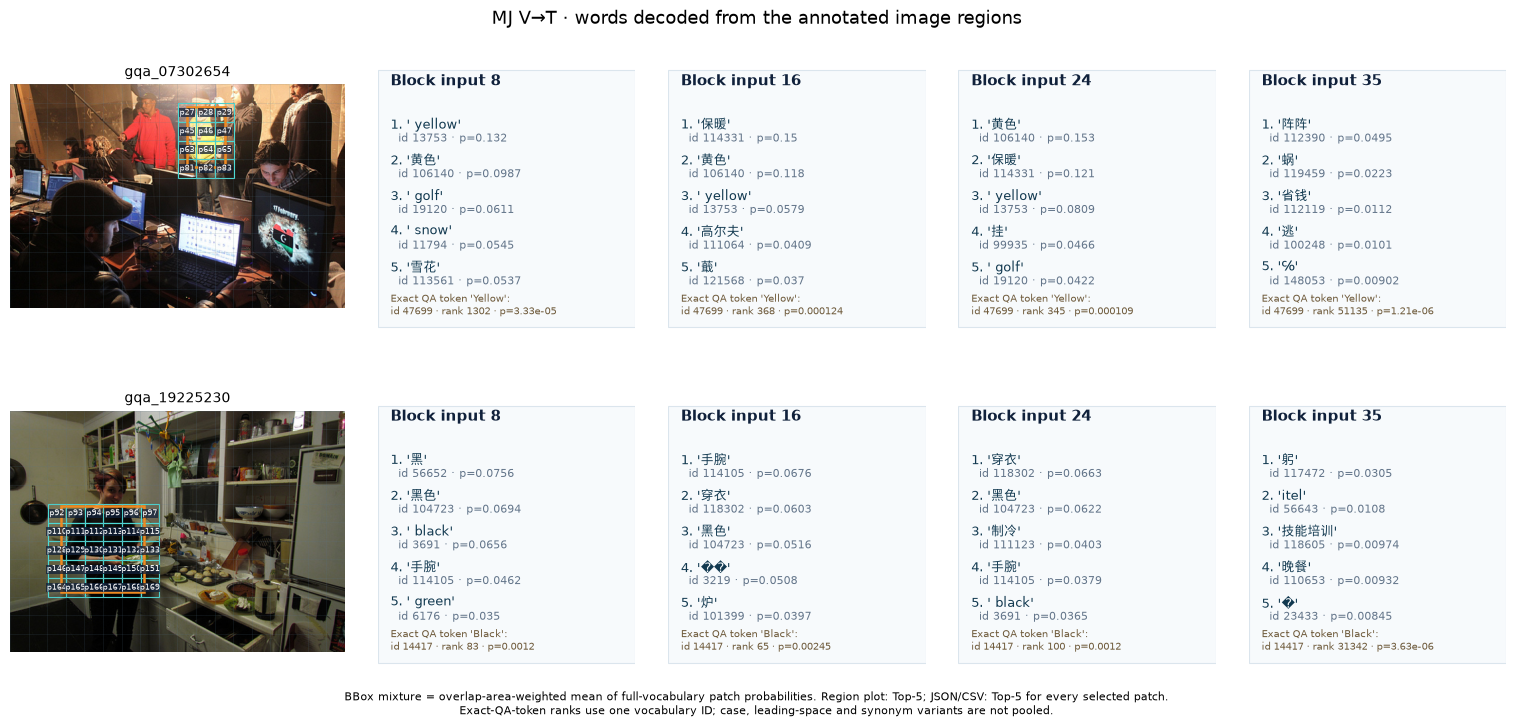

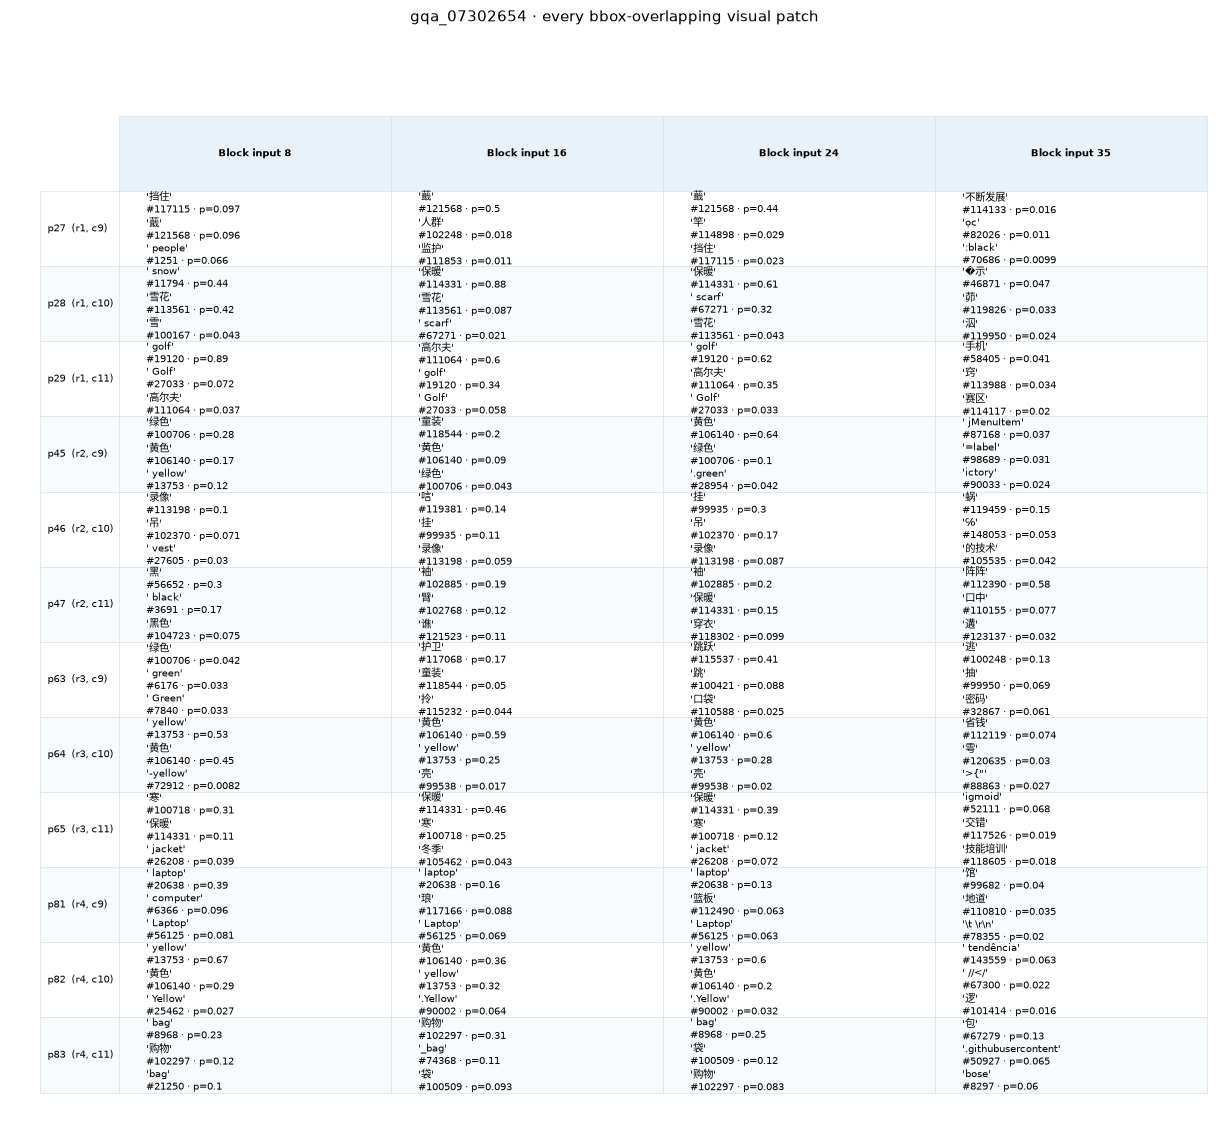

/tmp/ipykernel_1531593/3424224180.py:71: UserWarning: Glyph 3649 (\N{THAI CHARACTER SARA AE}) missing from font(s) Noto Sans CJK SC, DejaVu Sans.
  fig.savefig(OUT / f"mj-report-region-patches-{row['case']['id']}.png", dpi=150, bbox_inches="tight")
/tmp/ipykernel_1531593/3424224180.py:71: UserWarning: Glyph 3586 (\N{THAI CHARACTER KHO KHAI}) missing from font(s) Noto Sans CJK SC, DejaVu Sans.
  fig.savefig(OUT / f"mj-report-region-patches-{row['case']['id']}.png", dpi=150, bbox_inches="tight")
/tmp/ipykernel_1531593/3424224180.py:71: UserWarning: Glyph 3609 (\N{THAI CHARACTER NO NU}) missing from font(s) Noto Sans CJK SC, DejaVu Sans.
  fig.savefig(OUT / f"mj-report-region-patches-{row['case']['id']}.png", dpi=150, bbox_inches="tight")


/data/gexinh/miniconda3/lib/python3.12/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 3649 (\N{THAI CHARACTER SARA AE}) missing from font(s) Noto Sans CJK SC, DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/data/gexinh/miniconda3/lib/python3.12/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 3586 (\N{THAI CHARACTER KHO KHAI}) missing from font(s) Noto Sans CJK SC, DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/data/gexinh/miniconda3/lib/python3.12/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 3609 (\N{THAI CHARACTER NO NU}) missing from font(s) Noto Sans CJK SC, DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


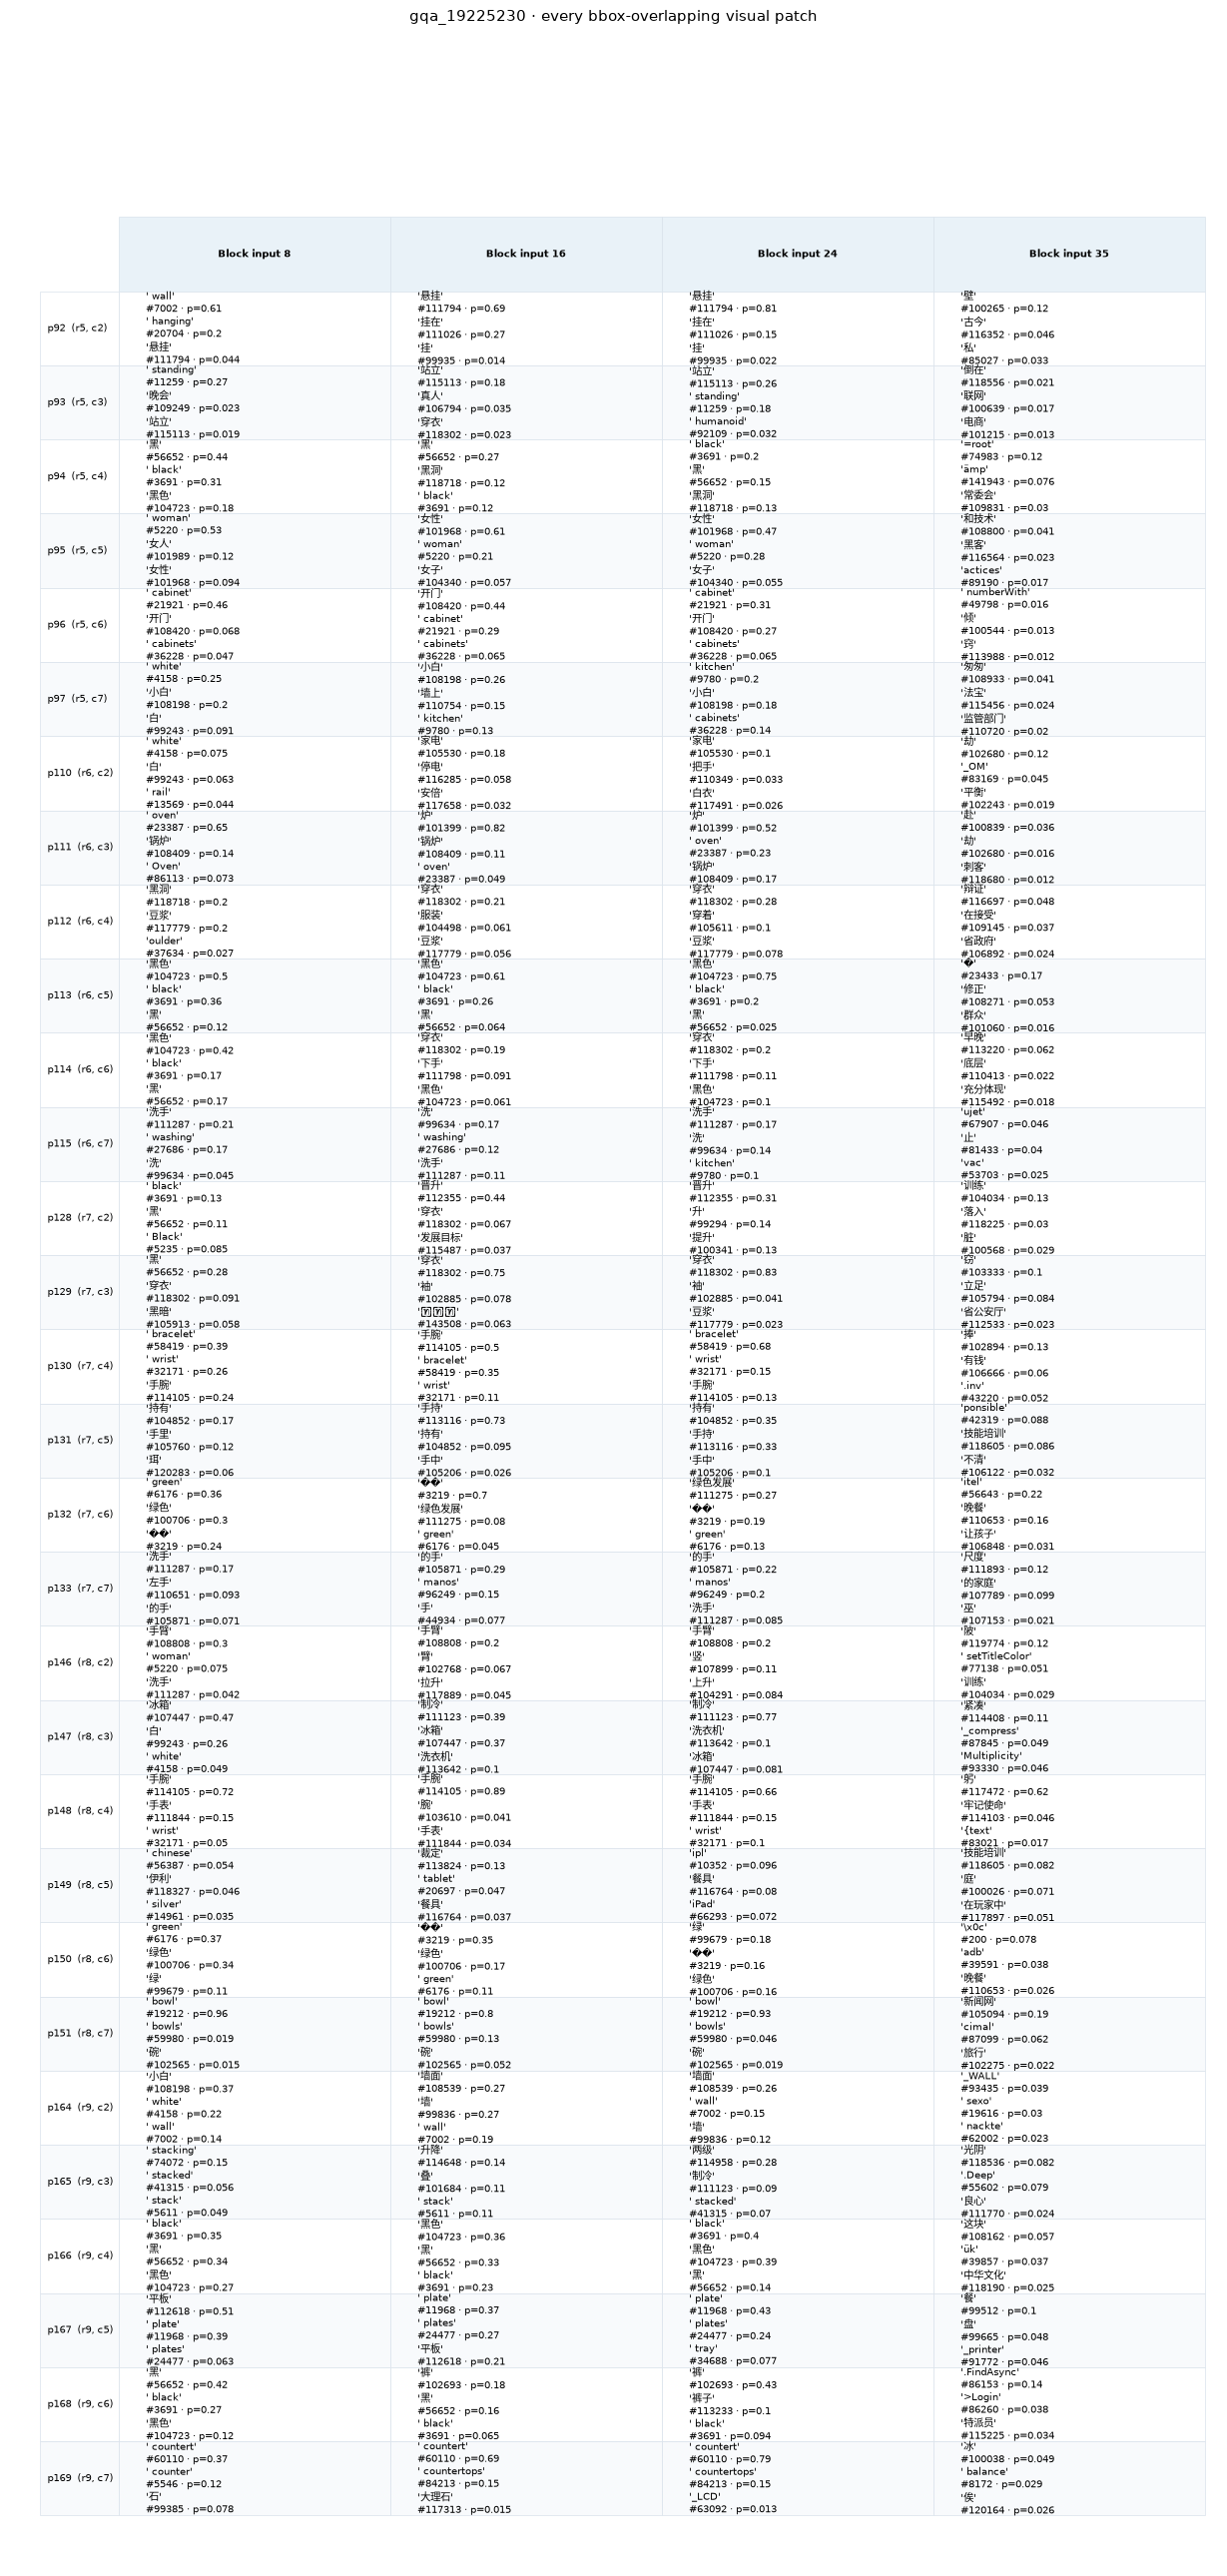

In [7]:
region_rows = [row for row in rows if row["bbox"] is not None]
region_reports = []
for row in region_rows:
    report = region_token_readout(
        row["vt"], tokenizer, grid_shape=row["grid"], image_size=row["image"].size,
        bbox=row["bbox"], top_k=REGION_TOP_K, reference_token_id=row["positive"],
    )
    report.update(case_id=row["case"]["id"], model_id=MODEL_ID, revision=revision,
                  question=row["case"]["question"], reference_answer=row["record"]["answer"])
    row["region"] = report
    region_reports.append(report)
    print("\nVisual bbox vocabulary readout:", report["case_id"],
          "patches", [p["patch_index"] for p in report["patches"]])
    for layer in report["layer_readouts"]:
        print("Block input", layer["layer"],
              [(t["token_repr"], t["token_id"], round(t["probability"], 6))
               for t in layer["region_top_tokens"]],
              "exact QA token rank", layer["region_reference"]["rank"])

(OUT / "mj-report-region-tokens.json").write_text(
    json.dumps(region_reports, ensure_ascii=False, indent=2, allow_nan=False) + "\n")
# Export every selected patch, layer and raw Top-k token, with post-hoc
# reference measurements as separately labelled rows. No showcase tensors are loaded.
fields = ["case_id", "scope", "record_type", "layer", "patch_index", "sequence_position",
          "row", "column", "intersection_area", "region_weight", "top_k_position",
          "token_id", "token", "token_repr", "logit", "probability", "reference_rank"]
with (OUT / "mj-report-region-tokens.csv").open("w", newline="", encoding="utf-8") as stream:
    writer = csv.DictWriter(stream, fieldnames=fields)
    writer.writeheader()
    for report in region_reports:
        for layer in report["layer_readouts"]:
            for rank, token in enumerate(layer["region_top_tokens"], 1):
                writer.writerow({"case_id": report["case_id"], "scope": "bbox_probability_mixture",
                    "record_type": "top_k", "layer": layer["layer"], "top_k_position": rank, **token})
            reference = dict(layer["region_reference"])
            reference["reference_rank"] = reference.pop("rank")
            writer.writerow({"case_id": report["case_id"], "scope": "bbox_probability_mixture",
                "record_type": "reference_posthoc", "layer": layer["layer"], **reference})
            for patch, decoded in zip(report["patches"], layer["patches"]):
                identity = {name: patch[name] for name in
                    ("patch_index", "sequence_position", "row", "column", "intersection_area", "region_weight")}
                for rank, token in enumerate(decoded["top_tokens"], 1):
                    writer.writerow({"case_id": report["case_id"], "scope": "visual_patch",
                        "record_type": "top_k", "layer": layer["layer"], "top_k_position": rank,
                        **identity, **token})
                reference = dict(decoded["reference"])
                reference["reference_rank"] = reference.pop("rank")
                writer.writerow({"case_id": report["case_id"], "scope": "visual_patch",
                    "record_type": "reference_posthoc", "layer": layer["layer"], **identity, **reference})

fig, axes = plt.subplots(len(region_rows), len(LAYERS) + 1,
    figsize=(15.3, 3.65 * len(region_rows)), squeeze=False,
    gridspec_kw={"width_ratios": [1.3] + [1.] * len(LAYERS)})
for row, row_axes in zip(region_rows, axes):
    plot_region_tokens(row["image"], row["region"], top_k=min(5, REGION_TOP_K),
        layer_labels=[f"Block input {layer}" for layer in LAYERS],
        title=row["case"]["id"], axes=row_axes)
fig.suptitle("MJ V→T · words decoded from the annotated image regions", y=.99, fontsize=13)
fig.subplots_adjust(left=.012, right=.99, top=.92, bottom=.09, wspace=.12, hspace=.24)
fig.text(.5, .025,
    "BBox mixture = overlap-area-weighted mean of full-vocabulary patch probabilities. "
    f"Region plot: Top-{min(5, REGION_TOP_K)}; JSON/CSV: Top-{REGION_TOP_K} for every selected patch.\n"
    "Exact-QA-token ranks use one vocabulary ID; case, leading-space and synonym variants are not pooled.",
    ha="center", fontsize=8)
fig.savefig(OUT / "mj-report-region-tokens.png", dpi=180, bbox_inches="tight")
plt.show()
for row in region_rows:
    fig, ax = plot_region_patch_tokens(row["region"], top_k=min(3, REGION_TOP_K),
        layer_labels=[f"Block input {layer}" for layer in LAYERS],
        title=row["case"]["id"] + " · every bbox-overlapping visual patch")
    fig.savefig(OUT / f"mj-report-region-patches-{row['case']['id']}.png", dpi=150, bbox_inches="tight")
    plt.show()


## 7. Supplement: selected-answer heatmaps and text-position controls

Inspect the original eight image/question inputs, then the selected reference-versus-foil visual readout heatmaps. These heatmaps display two supplied vocabulary scores and do not replace the unrestricted bbox word experiment above. Only supplied GQA boxes are drawn.

The final set of curves reads the **last text prompt position**, which can attend to image and question. MJ, same-state plain and native-final margins are kept separate. These are T→T measurements, not per-patch vocabulary outputs, and plain readout is not labelled Jacobian Lens.


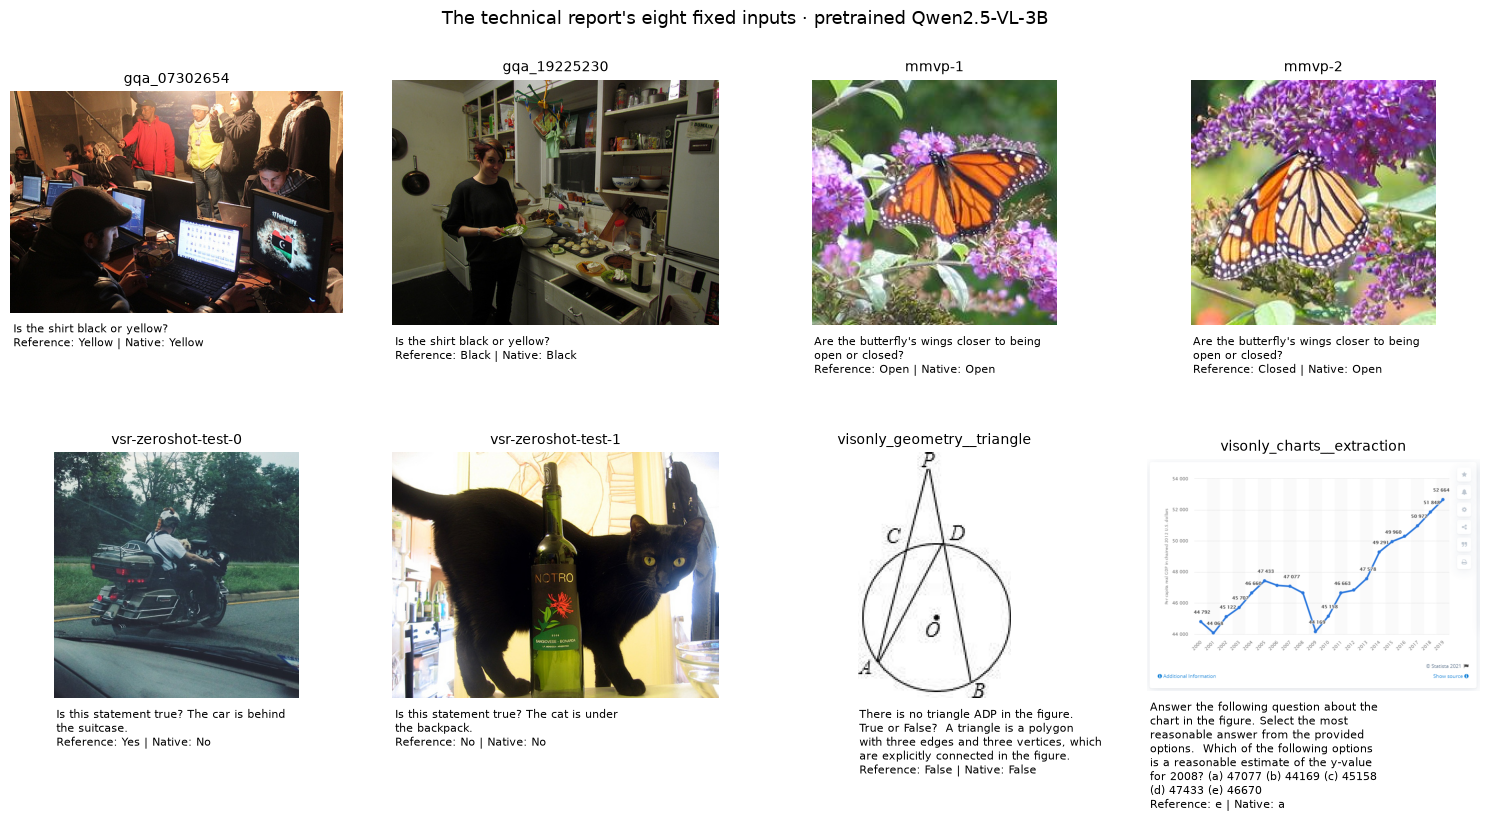

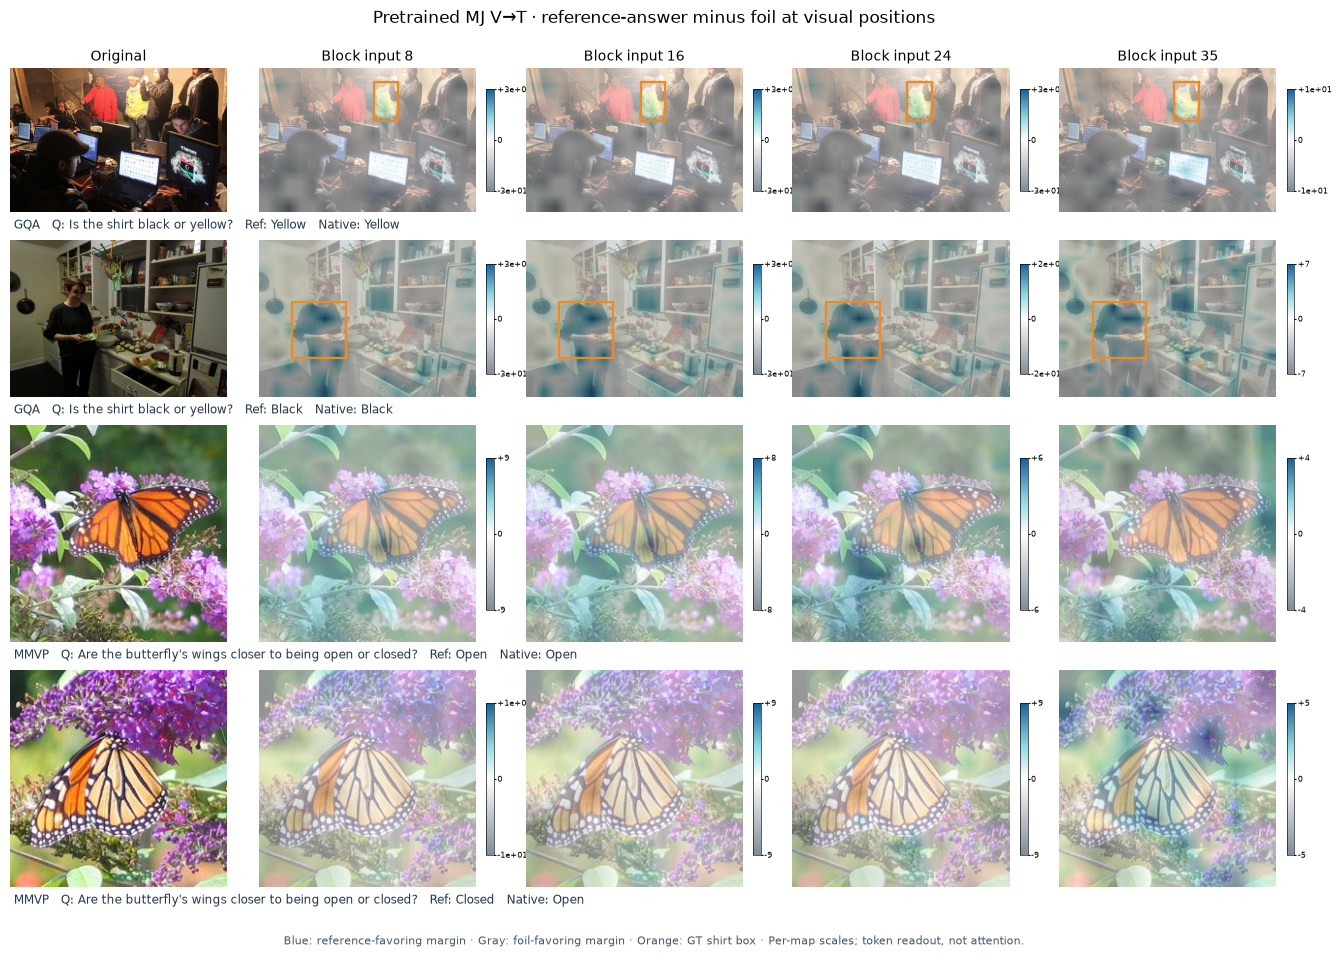

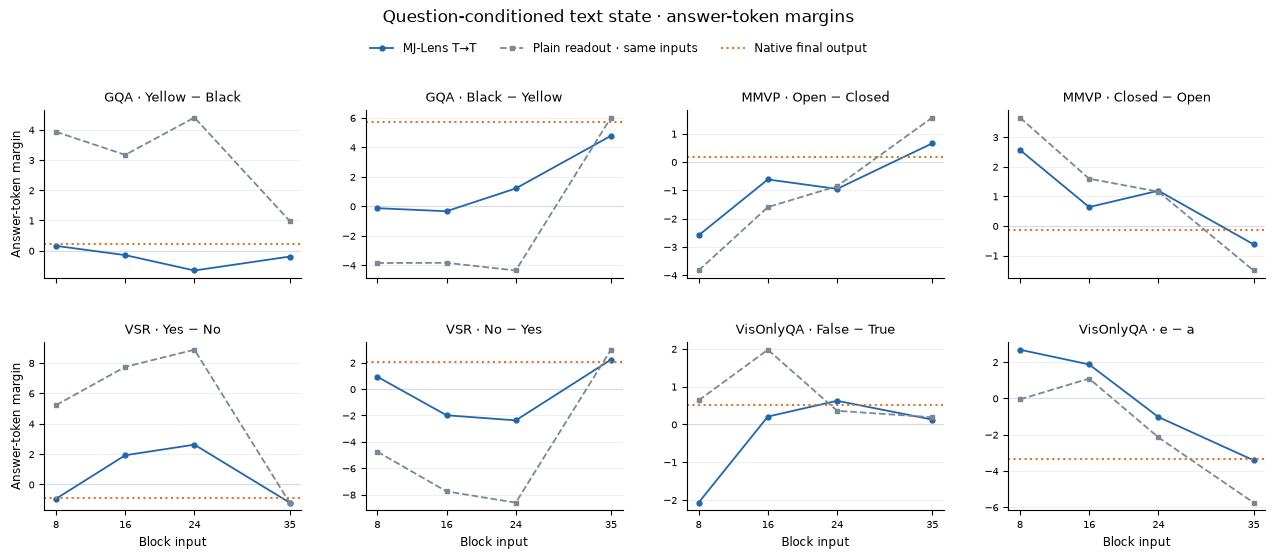

In [8]:
fig, axes = plt.subplots(2, 4, figsize=(15, 8), squeeze=False)
for row, ax in zip(rows, axes.flat):
    ax.imshow(Image.open(row["case"]["local_image"]).convert("RGB"))
    ax.axis("off")
    ax.set_title(row["case"]["id"], fontsize=10)
    ax.text(.01, -.04, textwrap.fill(row["case"]["question"], 42) +
            f"\nReference: {row['record']['answer']} | Native: {row['record']['generated']}",
            transform=ax.transAxes, va="top", fontsize=8)
fig.suptitle("The technical report's eight fixed inputs · pretrained Qwen2.5-VL-3B", fontsize=13)
fig.tight_layout(rect=(0, 0, 1, .96), h_pad=5)
fig.savefig(OUT / "mj-report-inputs.png", dpi=180, bbox_inches="tight")
plt.show()

from matplotlib.colors import LinearSegmentedColormap
from matplotlib.gridspec import GridSpecFromSubplotSpec
from matplotlib.ticker import FuncFormatter

spatial_rows = rows[:4]
# Match each row's height to its measured image aspect ratio. Captions occupy
# separate narrow strips, so landscape images do not create blank square rows.
row_ratios = [row["image"].height / row["image"].width for row in spatial_rows]
height_ratios = [value for ratio in row_ratios for value in (ratio, .105)]
fig = plt.figure(figsize=(13.2, 2.48 * sum(row_ratios) + 1.2))
grid = fig.add_gridspec(2 * len(spatial_rows), 1 + len(LAYERS),
    height_ratios=height_ratios, width_ratios=[1.] + [1.1] * len(LAYERS),
    left=.012, right=.985, bottom=.045, top=.925, wspace=.12, hspace=.025)
readout_cmap = LinearSegmentedColormap.from_list("mj_spatial_signed", [
    (0., "#7f8d99"), (.5, "#ffffff"), (.72, "#8dd7e1"), (1., "#155f9e"),
])
for row_index, row in enumerate(spatial_rows):
    ax = fig.add_subplot(grid[2 * row_index, 0])
    ax.imshow(row["image"])
    ax.axis("off")
    if row_index == 0:
        ax.set_title("Original", fontsize=10, pad=5)
    for column, layer in enumerate(LAYERS, 1):
        # The narrow colorbar belongs to this map only. Its symmetric limits
        # expose the measured sign and units without changing any readout.
        cell = GridSpecFromSubplotSpec(1, 2, subplot_spec=grid[2 * row_index, column],
                                      width_ratios=[1., .035], wspace=.055)
        map_ax = fig.add_subplot(cell[0, 0])
        plot_mj_visual_readout(row["image"], row["vt"], positive_token_id=row["positive"],
            negative_token_id=row["negative"], grid_shape=row["grid"], layer=layer,
            bbox=row["bbox"], token_label=row["record"]["answer"], negative_label=row["record"]["foil"],
            image_alpha=.45, alpha=1., cmap=readout_cmap, colorbar=False, ax=map_ax)
        map_ax.set_title(f"Block input {layer}" if row_index == 0 else "", fontsize=10, pad=5)
        bar_ax = fig.add_subplot(cell[0, 1])
        # Vertically center a short bar next to the actual image artist.
        bar_box = bar_ax.get_position()
        bar_ax.set_position([bar_box.x0, bar_box.y0 + .15 * bar_box.height,
                             bar_box.width, .70 * bar_box.height])
        artist = map_ax.images[1]
        limits = [artist.norm.vmin, 0., artist.norm.vmax]
        colorbar = fig.colorbar(artist, cax=bar_ax, ticks=limits,
            format=FuncFormatter(lambda value, _: "0" if value == 0 else f"{value:+.1g}"))
        colorbar.ax.tick_params(labelsize=5.7, length=1.5, pad=1)
        colorbar.outline.set_linewidth(.45)
    caption_ax = fig.add_subplot(grid[2 * row_index + 1, :])
    caption_ax.axis("off")
    caption_ax.text(.003, .55,
        f"{row['case']['dataset']}   Q: {row['case']['question']}   "
        f"Ref: {row['record']['answer']}   Native: {row['record']['generated']}",
        transform=caption_ax.transAxes, ha="left", va="center", fontsize=8.5, color="#26384c")
fig.suptitle("Pretrained MJ V→T · reference-answer minus foil at visual positions", y=.985, fontsize=12)
fig.text(.5, .012,
    "Blue: reference-favoring margin · Gray: foil-favoring margin · Orange: GT shirt box · "
    "Per-map scales; token readout, not attention.", ha="center", fontsize=7.8, color="#45566b")
fig.savefig(OUT / "mj-report-spatial.png", dpi=180, bbox_inches="tight")
plt.show()

# Question-conditioned text readouts on all eight report examples.
fig, axes = plt.subplots(2, 4, figsize=(13.2, 5.6), squeeze=False, sharex=True)
for index, (row, ax) in enumerate(zip(rows, axes.flat)):
    plot_mj_text_comparison(row["tt"], row["plain"], row["native"],
        positive_token_id=row["positive"], negative_token_id=row["negative"], ax=ax)
    ax.set_title(f"{row['case']['dataset']} · {row['record']['answer']} − {row['record']['foil']}", fontsize=9.5)
    ax.set_xlabel("Block input" if index >= 4 else "", fontsize=8.5)
    ax.set_ylabel("Answer-token margin" if index % 4 == 0 else "", fontsize=8.5)
    ax.tick_params(labelsize=7.5)
    ax.grid(axis="y", color="#d9dfe6", linewidth=.6, alpha=.55)
    ax.spines[["top", "right"]].set_visible(False)
    for line in ax.lines[:2]:
        line.set_markersize(3.5)
        line.set_linewidth(1.3)
    ax.get_legend().remove()
handles, legend_labels = axes[0, 0].get_legend_handles_labels()
fig.suptitle("Question-conditioned text state · answer-token margins", y=.99, fontsize=12)
fig.legend(handles, legend_labels, loc="upper center", bbox_to_anchor=(.5, .95),
           ncol=3, frameon=False, fontsize=8.5)
fig.subplots_adjust(left=.065, right=.99, bottom=.095, top=.81, wspace=.25, hspace=.38)
fig.savefig(OUT / "mj-report-text-controls.png", dpi=180, bbox_inches="tight")
plt.show()


## 8. Supplement: native-output agreement and causal-order control

Compare native-output KL divergence and top-20 overlap at the last text position. Fidelity and reference-answer correctness are distinct measurements.

Then change the later question while matching sequence length and keeping image bytes, native grid and all image-prefix IDs identical. This controls TF32 matrix-shape differences and checks the expected causal-order boundary: the image-source state cannot depend on future question words.


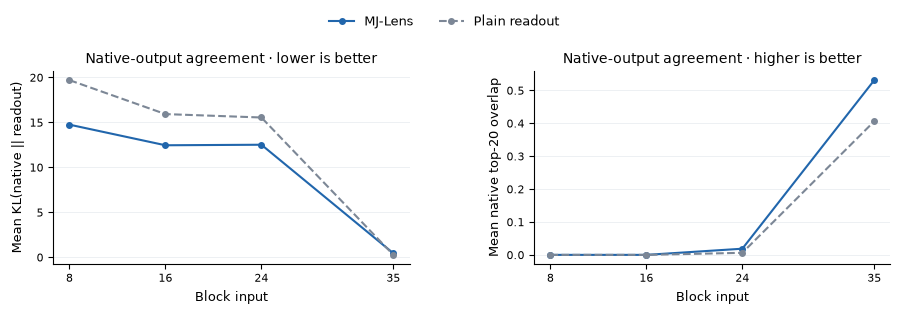

Same-image visual readout change under a later-question swap: 0.0
Length-matched questions share the exact image prefix; this is a causal-order check.


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(9.2, 3.1))
for name, color, style in (("mj", "#2166ac", "-"), ("plain", "#7c8796", "--")):
    kl = torch.tensor([[m[name + "_kl_native"] for m in r["metrics"]] for r in records])
    overlap = torch.tensor([[m[name + "_native_top20_overlap"] for m in r["metrics"]] for r in records])
    label = "MJ-Lens" if name == "mj" else "Plain readout"
    axes[0].plot(LAYERS, kl.mean(0), style, marker="o", markersize=4, color=color, label=label)
    axes[1].plot(LAYERS, overlap.mean(0), style, marker="o", markersize=4, color=color, label=label)
axes[0].set(xlabel="Block input", ylabel="Mean KL(native || readout)", title="Native-output agreement · lower is better")
axes[1].set(xlabel="Block input", ylabel="Mean native top-20 overlap", title="Native-output agreement · higher is better")
for ax in axes:
    ax.set_xticks(LAYERS)
    ax.tick_params(labelsize=8)
    ax.xaxis.label.set_size(9)
    ax.yaxis.label.set_size(9)
    ax.title.set_size(10)
    ax.grid(axis="y", color="#d9dfe6", linewidth=.6, alpha=.55)
    ax.spines[["top", "right"]].set_visible(False)
handles, legend_labels = axes[0].get_legend_handles_labels()
fig.legend(handles, legend_labels, loc="upper center", bbox_to_anchor=(.5, 1.02),
           ncol=2, frameon=False, fontsize=9)
fig.subplots_adjust(left=.075, right=.985, bottom=.18, top=.80, wspace=.35)
fig.savefig(OUT / "mj-report-fidelity.png", dpi=180, bbox_inches="tight")
plt.show()

first = rows[0]
swap_question = ("Is the shirt red or blue?\n"
                 "Answer with exactly one of: Red, Blue. Do not add punctuation or explanation.")
_, swapped_inputs = prepare_image_text(Image.open(first["case"]["local_image"]).convert("RGB"),
                                        swap_question, EVALUATION_PIXELS)
# Match sequence length and all image-prefix inputs as well as image bytes.
# With TF32, a shorter suffix can select different matrix kernels and perturb
# the computed prefix even though the mathematical decoder is strictly causal.
original_ids, swapped_ids = first["inputs"]["input_ids"], swapped_inputs["input_ids"]
prefix_end = int(first["vt"].tensors["positions"][:, 1].max()) + 1
if (original_ids.shape != swapped_ids.shape
        or not torch.equal(original_ids[:, :prefix_end], swapped_ids[:, :prefix_end])
        or not torch.equal(first["inputs"]["pixel_values"], swapped_inputs["pixel_values"])
        or not torch.equal(first["inputs"]["image_grid_thw"], swapped_inputs["image_grid_thw"])):
    raise ValueError("question-swap control requires identical image-prefix inputs and sequence lengths")
original_control = methods["visual"].run(first["inputs"])
swapped = methods["visual"].run(swapped_inputs)
question_swap_max = float((original_control.tensors["logits"] - swapped.tensors["logits"]).abs().max())
print("Same-image visual readout change under a later-question swap:", question_swap_max)
print("Length-matched questions share the exact image prefix; this is a causal-order check.")


## 9. Save/load and reproducible records

Verify the identity-bound text transport round trip and save actual region and supplementary measurements to `experiment.json`. Raw region Top-k records are kept separately in JSON/CSV for inspection. The standalone script and this notebook contain the same executable steps; neither imports a cached experiment runner.


In [10]:
restored = probe.lens.mj(layers=LAYERS, source="text", target="text", binding=binding).load(OUT / "text_to_text")
replayed = restored.run(rows[0]["inputs"], tokens="last_prompt")
roundtrip = float((replayed.tensors["logits"] - rows[0]["tt"].tensors["logits"]).abs().max())
summary = {"model_id": MODEL_ID, "revision": revision, "dtype": str(DTYPE), "layers": LAYERS,
           "torch_version": torch.__version__,
           "transformers_version": __import__("transformers").__version__,
           "seed": 0, "float32_matmul_precision": torch.get_float32_matmul_precision(),
           "calibration_max_pixels": CALIBRATION_PIXELS, "evaluation_max_pixels": EVALUATION_PIXELS,
           "caption_max_tokens": MAX_CAPTION_TOKENS, "dim_batch": DIM_BATCH,
           "image_processor_class": type(processor.image_processor).__name__,
           "n_calibration": N_CALIBRATION, "calibration_image_ids": [r["image_id"] for r in calibration_records],
           "calibration_manifest_sha256": checksum(calibration_manifest),
           "report_manifest_sha256": checksum(report_manifest),
           "calibration": {k: v.calibration_report for k, v in methods.items()},
           "records": records, "bbox_region_readouts": region_reports,
           "region_top_k": REGION_TOP_K, "main_display": "bbox visual-token Top-k across declared layers",
           "question_swap_visual_max_abs_diff": question_swap_max,
           "question_swap_visual_relative_diff": question_swap_max / max(1., float(first["vt"].tensors["logits"].abs().max())),
           "question_swap_control": {"question": swap_question, "length_matched": True,
                                     "identical_image_prefix": True,
                                     "sequence_length": original_ids.shape[1]},
           "save_load_max_abs_diff": roundtrip,
           "scope": "Eight fixed report cases on one pretrained checkpoint; not a dataset benchmark or causal attribution study"}
(OUT / "experiment.json").write_text(json.dumps(summary, indent=2) + "\n")
print("case | reference | native | final MJ answer rank | plain answer rank")
for record in records:
    metric = record["metrics"][-1]
    print(record["id"], record["answer"], repr(record["generated"]),
          metric["mj_answer_rank"], metric["plain_answer_rank"], sep=" | ")
print("\nSupplement: last-TEXT-position vocabulary readouts (not visual patch decoding):")
print("case | block input | MJ top-1 token | plain top-1 token")
for record in records[:2]:
    for metric in record["metrics"]:
        print(record["id"], metric["layer"], repr(metric["mj_top_tokens"][0]),
              repr(metric["plain_top_tokens"][0]), sep=" | ")
write_status("complete", n_calibration=N_CALIBRATION, n_showcase=len(records),
             question_swap_visual_max_abs_diff=question_swap_max, save_load_max_abs_diff=roundtrip)
print("Figures and measured records:", OUT)


case | reference | native | final MJ answer rank | plain answer rank
gqa_07302654 | Yellow | 'Yellow' | 2 | 1
gqa_19225230 | Black | 'Black' | 1 | 1
mmvp-1 | Open | 'Open' | 1 | 1
mmvp-2 | Closed | 'Open' | 2 | 2
vsr-zeroshot-test-0 | Yes | 'No' | 2 | 2
vsr-zeroshot-test-1 | No | 'No' | 1 | 1
visonly_geometry__triangle | False | 'False' | 1 | 1
visonly_charts__extraction | e | 'a' | 6 | 5

Supplement: last-TEXT-position vocabulary readouts (not visual patch decoding):
case | block input | MJ top-1 token | plain top-1 token
gqa_07302654 | 8 | ' Gäste' | '(___'
gqa_07302654 | 16 | '点儿' | '个项目'
gqa_07302654 | 24 | '<|im_end|>' | '.bunifuFlatButton'
gqa_07302654 | 35 | 'Black' | 'Yellow'
gqa_19225230 | 8 | ' Gäste' | '(___'
gqa_19225230 | 16 | '点儿' | '胜负'
gqa_19225230 | 24 | '<|im_end|>' | '应用查看'
gqa_19225230 | 35 | 'Black' | 'Black'
{"status": "complete", "updated_unix": 1792978347.919491, "n_calibration": 32, "n_showcase": 8, "question_swap_visual_max_abs_diff": 0.0, "save_load_max_abs_d

Figures and measured records: outputs/mj_bbox_readouts


## Interpreting the readouts

Read the bbox word tables first. A plausible word is an observational prediction from a contextual visual state, not proof that the model exclusively represents that object or causally uses the word for its answer. Irrelevant, empty, special and subword candidates remain evidence and are kept visible.

The supplementary last-text-position experiment previously matched 4 of 8 references with MJ at block input 35, versus 5 with plain and native outputs. Those counts concern **T→T question answering**, not bbox word accuracy. Stable split-half operators do not guarantee useful vocabulary decoding, and this one-checkpoint case study is not a dataset-level benchmark.
